### **Naveed Anjum (Reg # 577607)**
##### Oct 7, 2026
---
## **Tutorial 6: Transfer Learning – Predicting Top-5 Labels with Pretrained Models**

## Step 1 — Import Libraries

In [61]:
import time, os, zipfile, urllib.request, copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch, torch.nn as nn, torch.optim as optim
import torchvision
from torchvision import models, transforms, datasets

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device: cuda


## Step 2 — Load and Preprocess the Image

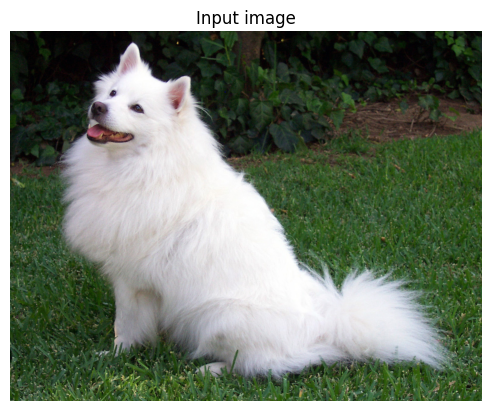

In [62]:
def get_image():
    path  =   "Image.jpg"
    url   =   "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"
    urllib.request.urlretrieve(url, path)
    return path

img_path  =   get_image()
image     =   Image.open(img_path).convert("RGB")
plt.imshow(image); plt.axis("off"); plt.title("Input image"); plt.show()

## Step 3 — Load Pretrained Models

In [63]:
MODEL_ZOO = {
    "vgg16":      (models.vgg16,        models.VGG16_Weights.IMAGENET1K_V1),
    "resnet50":   (models.resnet50,     models.ResNet50_Weights.IMAGENET1K_V2),
    "alexnet":    (models.alexnet,      models.AlexNet_Weights.IMAGENET1K_V1),
    "resnet101":  (models.resnet101,    models.ResNet101_Weights.IMAGENET1K_V2),
    "mobilenet":  (models.mobilenet_v2, models.MobileNet_V2_Weights.IMAGENET1K_V2),
}

def load_pretrained(name):
    fn, weights = MODEL_ZOO[name]
    model = fn(weights=weights).to(device).eval()
    return model, weights.transforms(), weights.meta["categories"]

loaded = {}
for n in MODEL_ZOO:
    loaded[n] = load_pretrained(n)
    nparams = sum(p.numel() for p in loaded[n][0].parameters())/1e6
    print(f"{n:10s} loaded  ({nparams:.1f}M parameters)")

vgg16      loaded  (138.4M parameters)
resnet50   loaded  (25.6M parameters)
alexnet    loaded  (61.1M parameters)
resnet101  loaded  (44.5M parameters)
mobilenet  loaded  (3.5M parameters)


## Step 4 — Make Predictions (Top-5)

In [64]:
@torch.no_grad()
def make_predictions(model, preprocess, categories, pil_img, k=5):
    x = preprocess(pil_img).unsqueeze(0).to(device)       # batch dimension added
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    logits = model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) * 1000
    probs = torch.softmax(logits, dim=1)[0]
    top = torch.topk(probs, k)
    return [(categories[i], p.item()) for p, i in zip(top.values, top.indices)], ms

def print_top5_predictions(name, pil_img):
    model, prep, cats = loaded[name]
    preds, ms = make_predictions(model, prep, cats, pil_img)
    print(f"\nTop 5 predictions for {name.upper()} ({ms:.1f} ms):")
    for i, (label, p) in enumerate(preds, 1):
        print(f"{i}. {label} ({p*100:.2f}% probability)")
    return preds

## Step 5 — Define Image Path
The path is the `img_path` variable set in Step 2 (upload or URL — no local Windows path needed on Colab).

In [65]:
print('Using image:', img_path)

Using image: Image.jpg


## Step 6 — Get Predictions from VGG16 and ResNet50

In [66]:
vgg_preds    = print_top5_predictions("vgg16", image)
resnet_preds = print_top5_predictions("resnet50", image)


Top 5 predictions for VGG16 (28.7 ms):
1. Samoyed (83.95% probability)
2. Pomeranian (3.30% probability)
3. Eskimo dog (1.68% probability)
4. white wolf (1.60% probability)
5. Great Pyrenees (1.22% probability)

Top 5 predictions for RESNET50 (12.6 ms):
1. Samoyed (43.66% probability)
2. white wolf (2.11% probability)
3. Pomeranian (1.32% probability)
4. Great Pyrenees (0.80% probability)
5. Eskimo dog (0.59% probability)


## Task 1 — Experiment with Different Architectures
AlexNet, ResNet-101 and MobileNet are compared with VGG16 / ResNet-50 on the same image.

In [67]:
results = {n: print_top5_predictions(n, image) for n in ["alexnet", "resnet101", "mobilenet"]}
results["vgg16"], results["resnet50"] = vgg_preds, resnet_preds


Top 5 predictions for ALEXNET (3.6 ms):
1. Samoyed (72.45% probability)
2. wallaby (13.94% probability)
3. Pomeranian (5.87% probability)
4. Angora (2.28% probability)
5. Arctic fox (1.25% probability)

Top 5 predictions for RESNET101 (24.0 ms):
1. Samoyed (78.09% probability)
2. white wolf (1.59% probability)
3. Pomeranian (1.34% probability)
4. keeshond (0.76% probability)
5. Eskimo dog (0.59% probability)

Top 5 predictions for MOBILENET (9.4 ms):
1. Samoyed (30.91% probability)
2. Pomeranian (5.10% probability)
3. keeshond (1.59% probability)
4. white wolf (1.43% probability)
5. Arctic fox (1.08% probability)


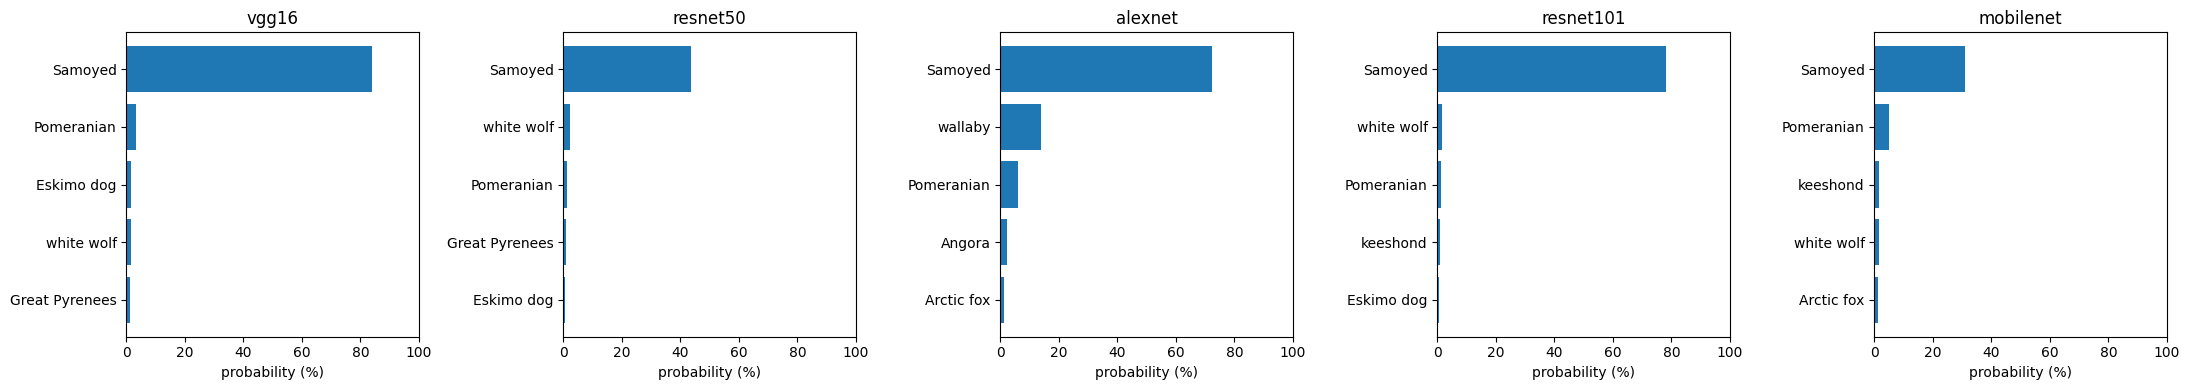

In [68]:
# Visual comparison of top-5 confidences
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, n in zip(axes, MODEL_ZOO):
    labels, probs = zip(*results[n])
    ax.barh(labels[::-1], np.array(probs[::-1])*100, color="tab:blue")
    ax.set_title(n); ax.set_xlabel("probability (%)"); ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

In [69]:
# Model comparison: size, speed, top-1 prediction
def benchmark(name, runs=20):
    model, prep, cats = loaded[name]
    x = prep(image).unsqueeze(0).to(device)
    with torch.no_grad():
        for _ in range(3): model(x)                       # warm-up
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(runs): model(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter()-t0)/runs*1000

print(f"{'model':10s} {'params(M)':>10s} {'ms/img':>8s}  top-1 (conf)")
for n in MODEL_ZOO:
    m = loaded[n][0]
    params = sum(p.numel() for p in m.parameters())/1e6
    top1 = results[n][0]
    print(f"{n:10s} {params:10.1f} {benchmark(n):8.1f}  {top1[0]} ({top1[1]*100:.1f}%)")

model       params(M)   ms/img  top-1 (conf)
vgg16           138.4     18.1  Samoyed (84.0%)
resnet50         25.6      6.0  Samoyed (43.7%)
alexnet          61.1      1.9  Samoyed (72.4%)
resnet101        44.5     12.1  Samoyed (78.1%)
mobilenet         3.5      5.3  Samoyed (30.9%)


## Task 2 — Transfer Learning on a New Dataset
We use the small **Hymenoptera (ants vs. bees)** dataset (~120 training images per class, auto-downloaded). Two strategies are compared:

1. **Feature extraction** – freeze the pretrained backbone, train only a new classifier head.
2. **Fine-tuning** – train all layers with a small learning rate.

To use your own data, put images in `data/train/<class>/` and `data/val/<class>/` and skip the download cell.

['ants', 'bees'] {'train': 244, 'val': 153}


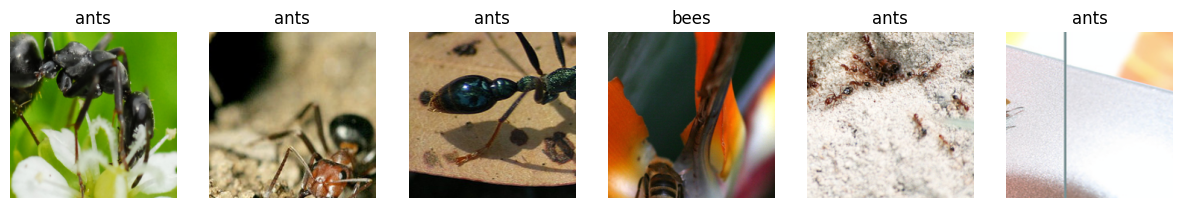

In [70]:
url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
if not os.path.exists("hymenoptera_data"):
    urllib.request.urlretrieve(url, "h.zip")
    with zipfile.ZipFile("h.zip") as z: z.extractall(".")
data_dir = "hymenoptera_data"

norm = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tfm = {
 "train": transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
                              transforms.ToTensor(), norm]),
 "val":   transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                              transforms.ToTensor(), norm]),
}
ds = {s: datasets.ImageFolder(os.path.join(data_dir, s), tfm[s]) for s in ["train","val"]}
dl = {s: torch.utils.data.DataLoader(ds[s], batch_size=32, shuffle=(s=="train"), num_workers=2) for s in ds}
class_names = ds["train"].classes
print(class_names, {s: len(ds[s]) for s in ds})

# show a few samples
inv = lambda t: (t.permute(1,2,0).numpy()*np.array([0.229,0.224,0.225])+np.array([0.485,0.456,0.406])).clip(0,1)
xb, yb = next(iter(dl["train"]))
fig, axs = plt.subplots(1, 6, figsize=(15, 3))
for a, x, y in zip(axs, xb, yb): a.imshow(inv(x)); a.set_title(class_names[y]); a.axis("off")
plt.show()

In [71]:
def build_model(arch, strategy, num_classes):
    """arch: resnet50 | mobilenet | alexnet | vgg16 | resnet101; strategy: 'feature_extract' or 'finetune'"""
    fn, weights = MODEL_ZOO[arch]
    m = fn(weights=weights)
    if strategy == "feature_extract":
        for p in m.parameters(): p.requires_grad = False
    # replace the final layer (new layer is trainable by default)
    if arch.startswith("resnet"):
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    else:                                   # vgg / alexnet / mobilenet: last item of classifier
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    return m.to(device)

def train_model(model, epochs=8, lr=1e-3):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = optim.SGD(params, lr=lr, momentum=0.9)
    sched = optim.lr_scheduler.StepLR(opt, step_size=4, gamma=0.1)
    crit = nn.CrossEntropyLoss()
    hist = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}
    best_w, best_acc = copy.deepcopy(model.state_dict()), 0
    for ep in range(epochs):
        for phase in ["train", "val"]:
            model.train(phase=="train")
            tot_loss = correct = 0
            for x, y in dl[phase]:
                x, y = x.to(device), y.to(device)
                opt.zero_grad()
                with torch.set_grad_enabled(phase=="train"):
                    out = model(x); loss = crit(out, y)
                    if phase == "train": loss.backward(); opt.step()
                tot_loss += loss.item()*x.size(0); correct += (out.argmax(1)==y).sum().item()
            if phase == "train": sched.step()
            n = len(ds[phase]); hist[phase+"_loss"].append(tot_loss/n); hist[phase+"_acc"].append(correct/n)
        if hist["val_acc"][-1] > best_acc:
            best_acc = hist["val_acc"][-1]; best_w = copy.deepcopy(model.state_dict())
        print(f"epoch {ep+1:2d}/{epochs} | train loss {hist['train_loss'][-1]:.3f} acc {hist['train_acc'][-1]:.3f}"
              f" | val loss {hist['val_loss'][-1]:.3f} acc {hist['val_acc'][-1]:.3f}")
    model.load_state_dict(best_w)
    return model, hist, best_acc

In [72]:
runs = {}
for arch in ["resnet50", "mobilenet"]:
    for strat, lr in [("feature_extract", 1e-3), ("finetune", 1e-3)]:
        print(f"\n=== {arch} | {strat} ===")
        m = build_model(arch, strat, len(class_names))
        t0 = time.time()
        m, h, best = train_model(m, epochs=20, lr=lr)
        runs[(arch, strat)] = dict(model=m, hist=h, best=best, time=time.time()-t0)


=== resnet50 | feature_extract ===
epoch  1/20 | train loss 0.692 acc 0.533 | val loss 0.640 acc 0.771
epoch  2/20 | train loss 0.653 acc 0.676 | val loss 0.577 acc 0.922
epoch  3/20 | train loss 0.589 acc 0.844 | val loss 0.519 acc 0.922
epoch  4/20 | train loss 0.531 acc 0.930 | val loss 0.474 acc 0.922
epoch  5/20 | train loss 0.489 acc 0.934 | val loss 0.470 acc 0.922
epoch  6/20 | train loss 0.490 acc 0.914 | val loss 0.468 acc 0.915
epoch  7/20 | train loss 0.493 acc 0.902 | val loss 0.465 acc 0.922
epoch  8/20 | train loss 0.484 acc 0.906 | val loss 0.460 acc 0.922
epoch  9/20 | train loss 0.478 acc 0.934 | val loss 0.461 acc 0.915
epoch 10/20 | train loss 0.485 acc 0.898 | val loss 0.457 acc 0.935
epoch 11/20 | train loss 0.474 acc 0.930 | val loss 0.459 acc 0.928
epoch 12/20 | train loss 0.484 acc 0.926 | val loss 0.460 acc 0.928
epoch 13/20 | train loss 0.478 acc 0.926 | val loss 0.454 acc 0.941
epoch 14/20 | train loss 0.486 acc 0.918 | val loss 0.454 acc 0.935
epoch 15/20 

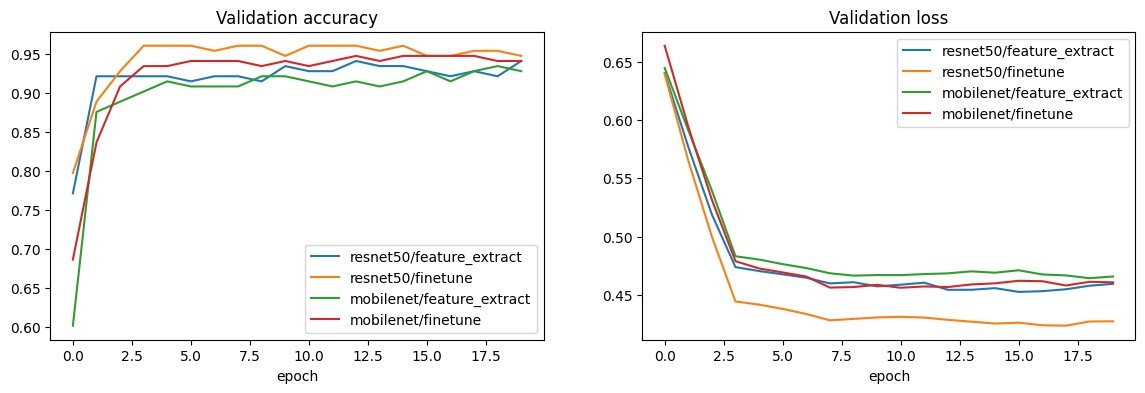

model      strategy         best val acc  time(s)
resnet50   feature_extract         0.941       59
resnet50   finetune                0.961       87
mobilenet  feature_extract         0.935       53
mobilenet  finetune                0.948       58


In [73]:
# Training curves
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for (arch, strat), r in runs.items():
    axs[0].plot(r["hist"]["val_acc"],  label=f"{arch}/{strat}")
    axs[1].plot(r["hist"]["val_loss"], label=f"{arch}/{strat}")
axs[0].set_title("Validation accuracy"); axs[1].set_title("Validation loss")
for a in axs: a.set_xlabel("epoch"); a.legend()
plt.show()

print(f"{'model':10s} {'strategy':16s} {'best val acc':>12s} {'time(s)':>8s}")
for (arch, strat), r in runs.items():
    print(f"{arch:10s} {strat:16s} {r['best']:12.3f} {r['time']:8.0f}")

Best configuration: ('resnet50', 'finetune')


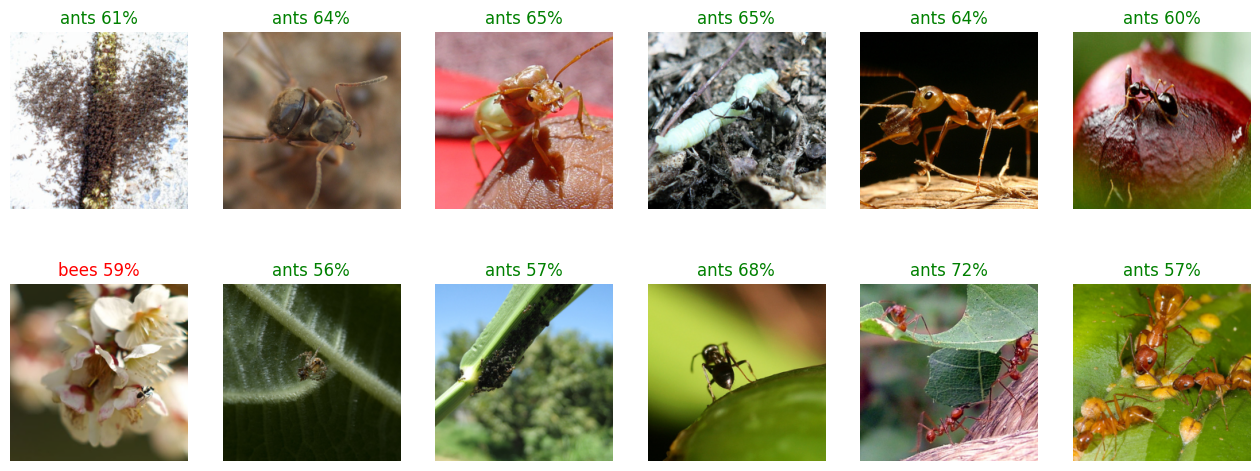

              precision    recall  f1-score   support

        ants       1.00      0.91      0.96        70
        bees       0.93      1.00      0.97        83

    accuracy                           0.96       153
   macro avg       0.97      0.96      0.96       153
weighted avg       0.96      0.96      0.96       153



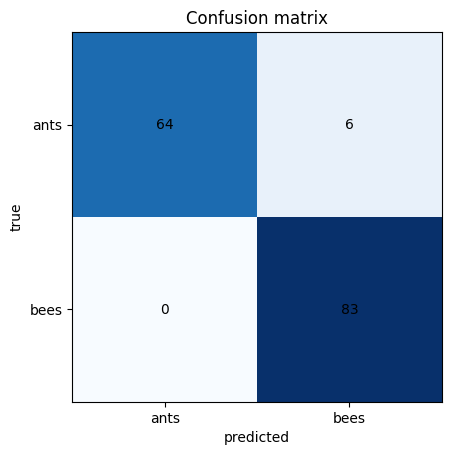

In [74]:
# Predictions of the best model on validation images + confusion matrix
best_key = max(runs, key=lambda k: runs[k]["best"])
best = runs[best_key]["model"].eval()
print("Best configuration:", best_key)

xs, ys = next(iter(dl["val"]))
with torch.no_grad(): pr = torch.softmax(best(xs.to(device)), 1).cpu()
fig, axs = plt.subplots(2, 6, figsize=(16, 6))
for a, x, y, p in zip(axs.ravel(), xs, ys, pr):
    c = p.argmax().item()
    a.imshow(inv(x)); a.axis("off")
    a.set_title(f"{class_names[c]} {p[c]*100:.0f}%", color="g" if c==y else "r")
plt.show()

from sklearn.metrics import confusion_matrix, classification_report
yt, yp = [], []
with torch.no_grad():
    for x, y in dl["val"]:
        yp += best(x.to(device)).argmax(1).cpu().tolist(); yt += y.tolist()
print(classification_report(yt, yp, target_names=class_names))
cm = confusion_matrix(yt, yp)
plt.imshow(cm, cmap="Blues"); plt.xticks(range(len(class_names)), class_names); plt.yticks(range(len(class_names)), class_names)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]): plt.text(j, i, cm[i,j], ha="center", va="center")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix"); plt.show()

torch.save(best.state_dict(), "best_transfer_model.pth")